# 09 · 소프트센서와 PAT·RTRT
### 실습으로 배우는 GMP AI — 강의 목차 ⑩ 소프트센서와 PAT 데이터 처리

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/StillWork/GMPAI/blob/main/09_Soft_Sensor_PAT_RTRT.ipynb)

| 항목 | 내용 |
|---|---|
| **학습 목표** | ① **소프트센서**(가상 계측) 개념과 구현 ② **배치 단위 검증**의 중요성 ③ 실시간 추정 시뮬레이션 ④ **RTRT** 적용 시점 결정 ⑤ 예측 구간(불확실성) 제시 ⑥ PAT·RTRT 규제 요건 |
| **데이터** | IndPenSim 100 배치 (예제 08과 동일) |
| **실행 환경** | CPU · 약 10분 |

> **핵심 질문**: "분석실 시험 결과를 기다리지 않고, 공정 중에 품질을 알 수 있는가?"
> 이것이 **PAT(공정분석기술)** 와 **RTRT(실시간 출하시험)** 의 목표이고, AI 가 가장 큰 가치를 내는 영역입니다.

In [1]:
%pip install -q koreanize-matplotlib
import koreanize_matplotlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt, time
import warnings; warnings.filterwarnings("ignore")
URL = "https://raw.githubusercontent.com/StillWork/data/refs/heads/master/100_Batches_IndPenSim_V3_no_raman.csv"
df = pd.read_csv(URL); df.columns = [c.split("(")[0].strip() for c in df.columns]
print(f"{df.shape[0]:,}행 × {df.shape[1]}열, {df['Batch ID'].nunique()}배치")

Note: you may need to restart the kernel to use updated packages.


113,935행 × 37열, 100배치


## 1. 소프트센서(Soft Sensor)란
**측정하기 어려운 값**을, **측정하기 쉬운 값들**로부터 모델이 추정하는 것. '가상 계측기'라고도 합니다.

| | 실제 센서 (하드웨어) | 소프트센서 (모델) |
|---|---|---|
| 페니실린 농도 | 시료 채취 → HPLC 분석 (수 시간 지연, 오염 위험) | pH·DO·배기가스 등으로 **실시간 추정** |
| 비용 | 분석 장비·인력 | 계산 자원만 |
| 빈도 | 수 시간에 1회 | **매 샘플(초/분 단위)** |
| 신뢰성 | 측정 표준 | 모델 성능에 의존 → **검증 필요** |

### PAT 프레임워크 (FDA, 2004)
> "최종 제품 시험이 아니라 **공정을 이해하고 제어**함으로써 품질을 보증한다"
- **공정 분석기**: NIR·라만·이미지 등 인라인 측정
- **다변량 해석**: PLS·머신러닝으로 스펙트럼·센서 → 품질
- **공정 제어**: 추정값으로 실시간 피드백 제어 (APC)
- **지속적 개선**: 축적 데이터로 모델·공정 개선

입력(온라인 센서) 20개 → 출력(CQA) 1개: Penicillin concentration


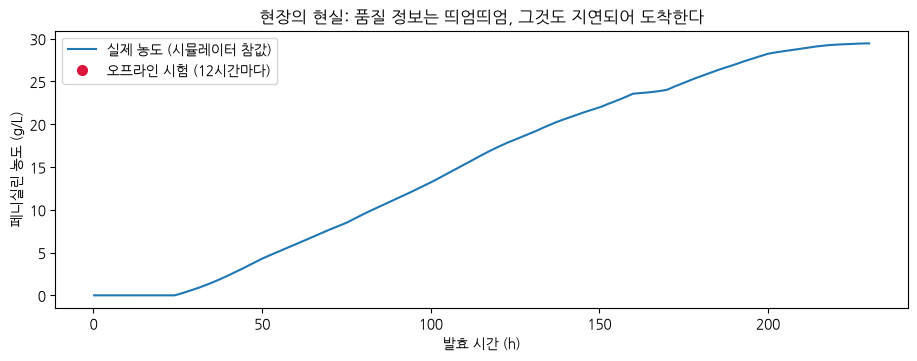

In [2]:
# 온라인 센서(실시간 측정 가능) vs 오프라인 측정(분석실 시험)
ONLINE = ["Aeration rate", "Agitator RPM", "Sugar feed rate", "Acid flow rate", "Base flow rate",
          "Heating/cooling water flow rate", "Water for injection/dilution", "Air head pressure",
          "Dissolved oxygen concentration", "Vessel Volume", "Vessel Weight", "pH", "Temperature",
          "Generated heat", "carbon dioxide percent in off-gas", "PAA flow", "Oil flow",
          "Oxygen Uptake Rate", "Oxygen in percent in off-gas", "Carbon evolution rate"]
TARGET = "Penicillin concentration"          # 실제로는 오프라인 시험이 필요한 CQA
print(f"입력(온라인 센서) {len(ONLINE)}개 → 출력(CQA) 1개: {TARGET}")

# 오프라인 측정은 드문드문 — 실제 현장을 모사
one = df[df["Batch ID"] == 20]
plt.figure(figsize=(11, 3.6))
plt.plot(one["Time"], one[TARGET], lw=1.5, label="실제 농도 (시뮬레이터 참값)")
off = one.iloc[::60]
plt.plot(off["Time"], off["Offline Penicillin concentration"], "o", ms=7, color="crimson", label="오프라인 시험 (12시간마다)")
plt.xlabel("발효 시간 (h)"); plt.ylabel("페니실린 농도 (g/L)"); plt.legend()
plt.title("현장의 현실: 품질 정보는 띄엄띄엄, 그것도 지연되어 도착한다"); plt.show()

## 2. ⭐ 소프트센서 모델 — 그리고 검증 방식이 성능을 좌우한다
**치명적인 함정**: 같은 배치의 데이터를 무작위로 나누면, 바로 옆 시점 데이터가 학습셋에 들어가 **거의 정답을 보고 푸는** 셈이 됩니다.
→ 반드시 **배치 단위로 분리**(GroupKFold)해야 새 배치에서의 실제 성능을 알 수 있습니다.

In [3]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_predict, KFold, GroupKFold
from sklearn.metrics import r2_score, mean_absolute_error

X, y, groups = df[ONLINE], df[TARGET], df["Batch ID"]
model = RandomForestRegressor(n_estimators=150, n_jobs=-1, random_state=0)

t = time.time()
pred_random = cross_val_predict(model, X, y, cv=KFold(5, shuffle=True, random_state=0))
pred_batch = cross_val_predict(model, X, y, cv=GroupKFold(5), groups=groups)
print(f"① 무작위 분할  R² = {r2_score(y, pred_random):.4f}  MAE = {mean_absolute_error(y, pred_random):.3f} g/L  ← 과대평가")
print(f"② 배치 단위 분할 R² = {r2_score(y, pred_batch):.4f}  MAE = {mean_absolute_error(y, pred_batch):.3f} g/L  ← 올바른 평가")
print(f"({time.time()-t:.0f}초)")

① 무작위 분할  R² = 0.9977  MAE = 0.188 g/L  ← 과대평가
② 배치 단위 분할 R² = 0.9343  MAE = 1.522 g/L  ← 올바른 평가
(224초)


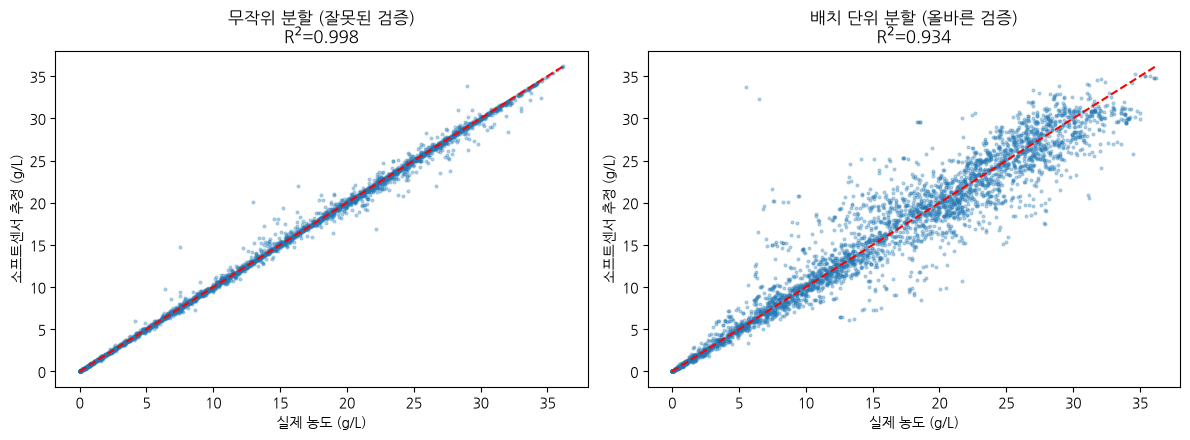

두 그림의 차이가 '검증 설계'의 중요성입니다. 규제 제출 자료에는 ②를 보고해야 합니다.


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for a, (p, name) in zip(ax, [(pred_random, "무작위 분할 (잘못된 검증)"), (pred_batch, "배치 단위 분할 (올바른 검증)")]):
    idx = np.random.RandomState(0).choice(len(y), 4000, replace=False)
    a.scatter(y.iloc[idx], p[idx], s=4, alpha=0.3)
    a.plot([0, y.max()], [0, y.max()], "r--")
    a.set_xlabel("실제 농도 (g/L)"); a.set_ylabel("소프트센서 추정 (g/L)")
    a.set_title(f"{name}\nR$^2$={r2_score(y, p):.3f}")
plt.tight_layout(); plt.show()
print("두 그림의 차이가 '검증 설계'의 중요성입니다. 규제 제출 자료에는 ②를 보고해야 합니다.")

## 3. 실시간 추정 시뮬레이션 — 새 배치에 적용하기
학습에 쓰지 않은 배치에서, 소프트센서가 **배치 전체 구간에서** 얼마나 잘 따라가는지 봅니다.

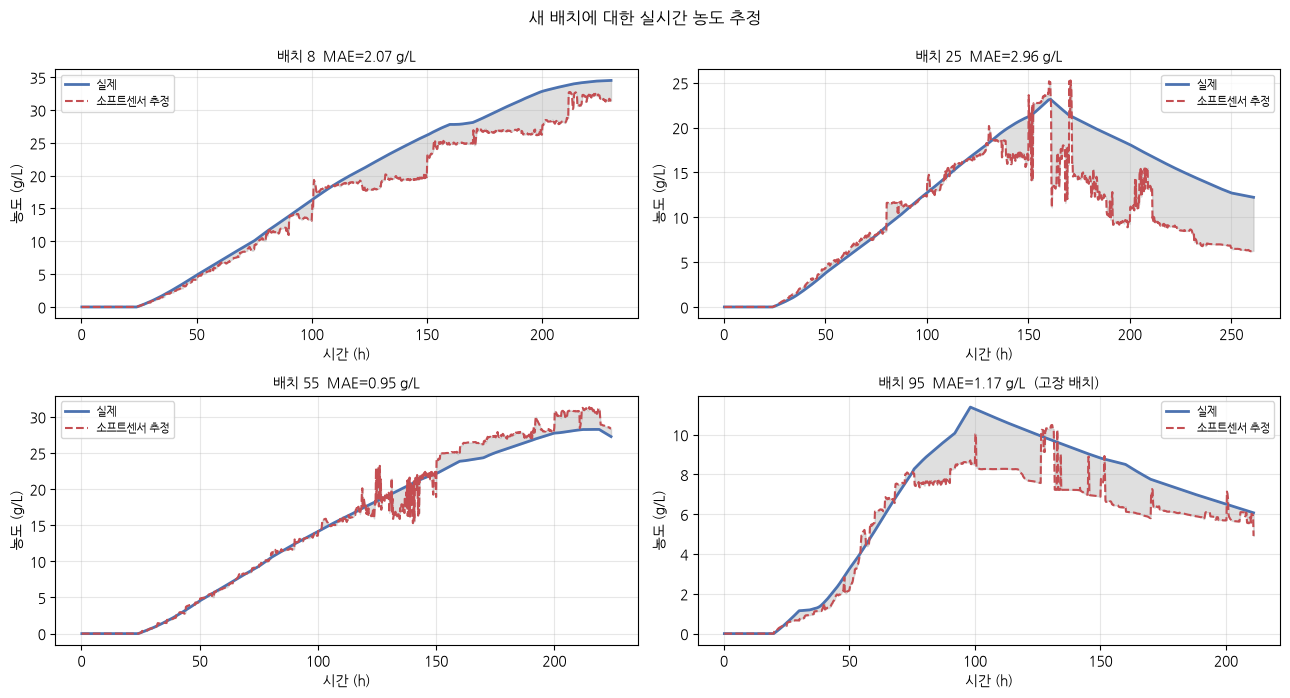

In [5]:
test_batches = [8, 25, 55, 95]          # 95번은 고장 배치
train_mask = ~df["Batch ID"].isin(test_batches)
soft = RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=0).fit(df.loc[train_mask, ONLINE], df.loc[train_mask, TARGET])

fig, ax = plt.subplots(2, 2, figsize=(13, 7))
for a, b in zip(ax.ravel(), test_batches):
    g = df[df["Batch ID"] == b].sort_values("Time")
    p = soft.predict(g[ONLINE])
    a.plot(g["Time"], g[TARGET], lw=2, label="실제", color="#4C72B0")
    a.plot(g["Time"], p, lw=1.5, ls="--", label="소프트센서 추정", color="#C44E52")
    a.fill_between(g["Time"], np.minimum(g[TARGET], p), np.maximum(g[TARGET], p), color="gray", alpha=0.25)
    err = mean_absolute_error(g[TARGET], p)
    a.set_title(f"배치 {b}  MAE={err:.2f} g/L" + ("  (고장 배치)" if b >= 91 else ""), fontsize=10)
    a.set_xlabel("시간 (h)"); a.set_ylabel("농도 (g/L)"); a.legend(fontsize=8); a.grid(alpha=0.3)
plt.suptitle("새 배치에 대한 실시간 농도 추정", y=0.99); plt.tight_layout(); plt.show()

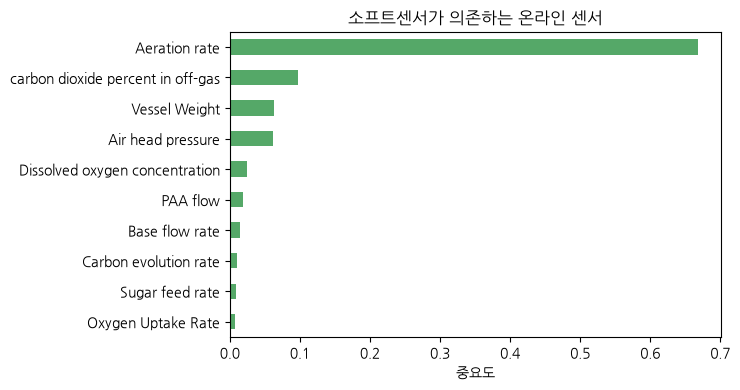

→ 상위 센서가 고장나면 소프트센서 성능이 급락합니다. 센서 이중화·교정 주기 관리의 근거가 됩니다.


In [6]:
# 변수 중요도 — 어떤 센서가 소프트센서를 지탱하는가 (센서 고장 시 영향 평가의 근거)
imp = pd.Series(soft.feature_importances_, index=ONLINE).sort_values().tail(10)
imp.plot.barh(figsize=(7.5, 4), color="#55A868")
plt.xlabel("중요도"); plt.title("소프트센서가 의존하는 온라인 센서"); plt.tight_layout(); plt.show()
print("→ 상위 센서가 고장나면 소프트센서 성능이 급락합니다. 센서 이중화·교정 주기 관리의 근거가 됩니다.")

## 4. 예측 불확실성 — "얼마나 확신하는가"를 함께 보고하기
규제 환경에서 **점 추정값만** 제시하는 것은 위험합니다. 랜덤포레스트는 개별 트리들의 예측 분포로 **예측 구간**을 만들 수 있습니다.

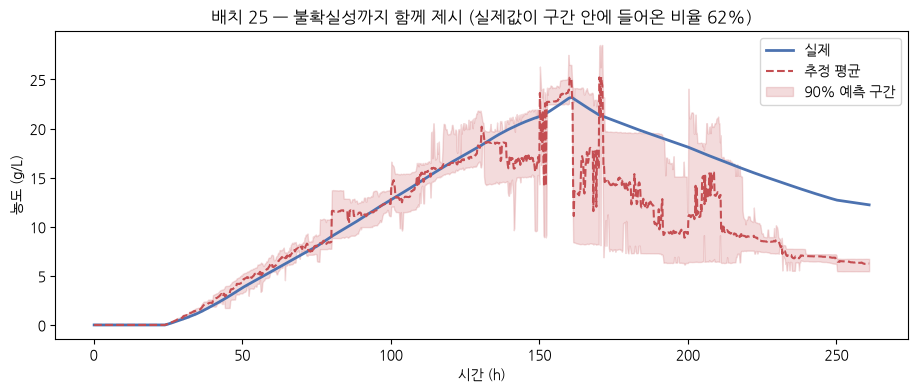

예측 구간이 넓어지는 구간 = 모델이 확신하지 못하는 구간 → 그 시점에는 실측 시험을 권고


In [7]:
b = 25
g = df[df["Batch ID"] == b].sort_values("Time")
tree_preds = np.stack([t.predict(g[ONLINE].values) for t in soft.estimators_])   # (트리 수, 시점)
mean_p, lo, hi = tree_preds.mean(0), np.percentile(tree_preds, 5, axis=0), np.percentile(tree_preds, 95, axis=0)
inside = ((g[TARGET].values >= lo) & (g[TARGET].values <= hi)).mean()

plt.figure(figsize=(11, 4))
plt.plot(g["Time"], g[TARGET], lw=2, label="실제", color="#4C72B0")
plt.plot(g["Time"], mean_p, lw=1.5, ls="--", color="#C44E52", label="추정 평균")
plt.fill_between(g["Time"], lo, hi, color="#C44E52", alpha=0.2, label="90% 예측 구간")
plt.xlabel("시간 (h)"); plt.ylabel("농도 (g/L)"); plt.legend()
plt.title(f"배치 {b} — 불확실성까지 함께 제시 (실제값이 구간 안에 들어온 비율 {inside:.0%})"); plt.show()
print("예측 구간이 넓어지는 구간 = 모델이 확신하지 못하는 구간 → 그 시점에는 실측 시험을 권고")

## 5. ⭐ RTRT — 실시간 출하시험은 언제부터 가능한가
**RTRT(Real Time Release Testing)**: 공정 데이터와 모델로 품질을 보증해 **최종 제품 시험의 일부를 대체**하는 방식 (ICH Q8/Q13, EU GMP Annex 17).

핵심 질문: **"배치가 몇 % 진행되면 최종 품질을 믿을 만하게 예측할 수 있는가?"**

In [8]:
final_P = df.groupby("Batch ID")[TARGET].max()
def features_at(frac):
    rows = {}
    for b, g in df.groupby("Batch ID"):
        g = g.sort_values("Time"); sub = g.iloc[:max(5, int(len(g) * frac))]
        f = {}
        for c in ONLINE:
            f[c + "_평균"] = sub[c].mean(); f[c + "_마지막"] = sub[c].iloc[-1]
            f[c + "_기울기"] = np.polyfit(np.arange(len(sub)), sub[c].values, 1)[0]
        f["현재_추정농도"] = soft.predict(sub[ONLINE].iloc[[-1]])[0]
        rows[b] = f
    return pd.DataFrame(rows).T

t = time.time(); curve = []
fracs = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
for frac in fracs:
    Xf = features_at(frac)
    pred = cross_val_predict(RandomForestRegressor(300, n_jobs=-1, random_state=0), Xf, final_P.loc[Xf.index],
                             cv=KFold(5, shuffle=True, random_state=0))
    curve.append({"진행률": frac, "R2": r2_score(final_P.loc[Xf.index], pred),
                  "MAE": mean_absolute_error(final_P.loc[Xf.index], pred), "예측": pred, "실제": final_P.loc[Xf.index].values})
cv_df = pd.DataFrame(curve)[["진행률", "R2", "MAE"]]
display(cv_df.round(3)); print(f"({time.time()-t:.0f}초)")

,진행률,R2,MAE
0,0.2,0.072,4.203
1,0.3,-0.034,4.282
2,0.4,0.317,3.549
3,0.5,0.598,2.873
4,0.6,0.556,3.055
5,0.7,0.773,2.131
6,0.8,0.891,1.363
7,0.9,0.877,1.271


(23초)


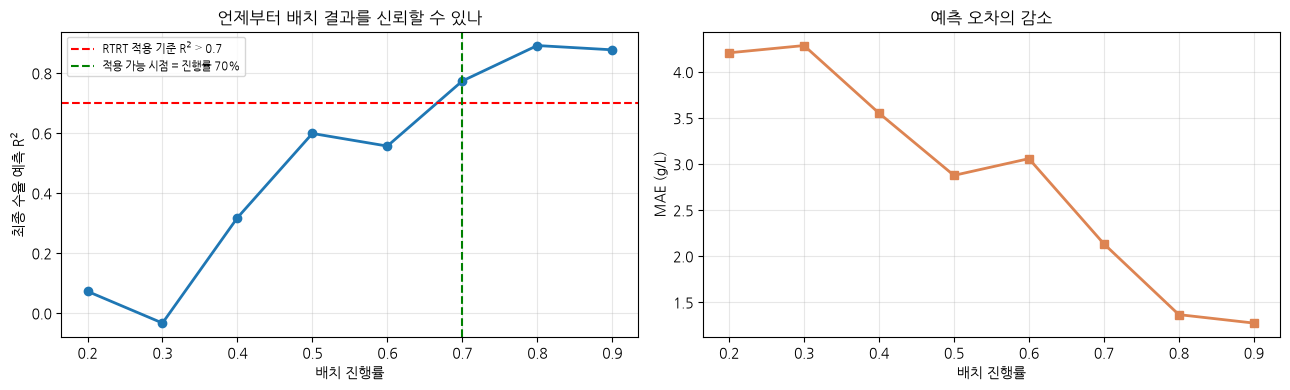

→ 배치 진행률 70% 시점부터 최종 수율을 기준 이상 정확도로 예측 가능
   남은 30% 구간은 '예측된 결과를 전제로' 후속 공정·출하 준비를 시작할 수 있습니다.


In [9]:
TARGET_R2 = 0.7                       # 회사가 정한 RTRT 적용 기준 (예시)
ok = cv_df[cv_df.R2 >= TARGET_R2]
rtrt_point = ok["진행률"].min() if len(ok) else None

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(cv_df["진행률"], cv_df["R2"], "o-", lw=2)
ax[0].axhline(TARGET_R2, color="red", ls="--", label=f"RTRT 적용 기준 R$^2$ ≥ {TARGET_R2}")
if rtrt_point: ax[0].axvline(rtrt_point, color="green", ls="--", label=f"적용 가능 시점 = 진행률 {rtrt_point:.0%}")
ax[0].set_xlabel("배치 진행률"); ax[0].set_ylabel("최종 수율 예측 R$^2$"); ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3)
ax[0].set_title("언제부터 배치 결과를 신뢰할 수 있나")
ax[1].plot(cv_df["진행률"], cv_df["MAE"], "s-", color="#DD8452", lw=2)
ax[1].set_xlabel("배치 진행률"); ax[1].set_ylabel("MAE (g/L)"); ax[1].grid(alpha=0.3); ax[1].set_title("예측 오차의 감소")
plt.tight_layout(); plt.show()
if rtrt_point:
    print(f"→ 배치 진행률 {rtrt_point:.0%} 시점부터 최종 수율을 기준 이상 정확도로 예측 가능")
    print(f"   남은 {100*(1-rtrt_point):.0f}% 구간은 '예측된 결과를 전제로' 후속 공정·출하 준비를 시작할 수 있습니다.")
else:
    print("→ 이 데이터에서는 설정한 기준을 만족하는 시점이 없습니다. 입력 변수 보강(PAT 센서 추가)이 필요합니다.")

배치 진행률 80% 시점에서 '최종 25.0 g/L 이상' 여부 판정
              precision    recall  f1-score   support

     25.0 미만      0.955     0.724     0.824        29
     25.0 이상      0.897     0.986     0.940        71

    accuracy                          0.910       100
   macro avg      0.926     0.855     0.882       100
weighted avg      0.914     0.910     0.906       100



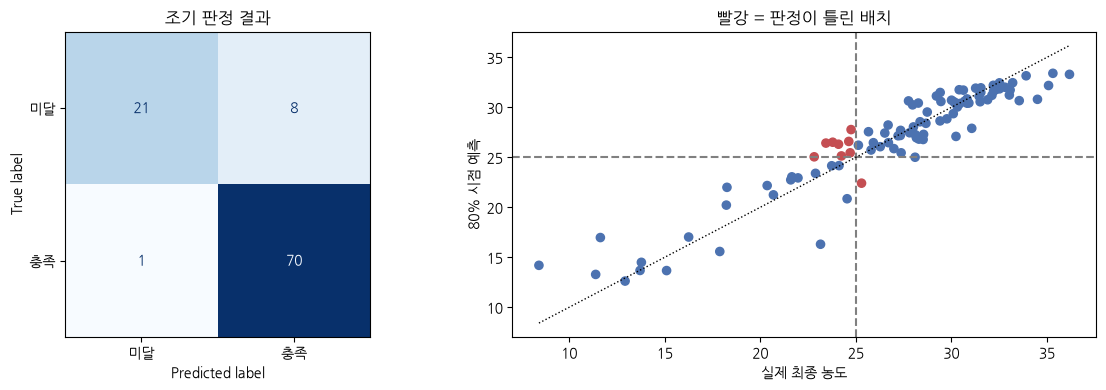

In [10]:
# RTRT 판정 시뮬레이션: 규격(예: 25 g/L 이상)을 만족할지 조기에 분류
SPEC = 25.0
best = curve[[c["진행률"] for c in curve].index(0.8)]
y_true_cls = (best["실제"] >= SPEC).astype(int)
y_pred_cls = (best["예측"] >= SPEC).astype(int)
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
print(f"배치 진행률 80% 시점에서 '최종 {SPEC} g/L 이상' 여부 판정")
print(classification_report(y_true_cls, y_pred_cls, target_names=[f"{SPEC} 미만", f"{SPEC} 이상"], digits=3))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ConfusionMatrixDisplay(confusion_matrix(y_true_cls, y_pred_cls), display_labels=["미달", "충족"]).plot(ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title("조기 판정 결과")
ax[1].scatter(best["실제"], best["예측"], s=35, c=np.where(y_true_cls == y_pred_cls, "#4C72B0", "#C44E52"))
ax[1].axhline(SPEC, color="gray", ls="--"); ax[1].axvline(SPEC, color="gray", ls="--")
ax[1].plot([best["실제"].min(), best["실제"].max()], [best["실제"].min(), best["실제"].max()], "k:", lw=1)
ax[1].set_xlabel("실제 최종 농도"); ax[1].set_ylabel("80% 시점 예측"); ax[1].set_title("빨강 = 판정이 틀린 배치")
plt.tight_layout(); plt.show()

## 6. RTRT 를 실제로 적용하려면 — 규제 요건
| 요건 | 내용 |
|---|---|
| **모델 검증** | 독립 배치로 예측 성능 입증. **배치 단위 분리** 필수 |
| **적용 범위 정의** | 모델이 유효한 공정 범위(Design Space) 명시 — 벗어나면 기존 시험으로 전환 |
| **모델 유지관리** | 성능 모니터링·주기적 재검증, **재학습 시 변경관리** (예제 11) |
| **대체 시험 절차** | 모델 사용 불가 시(센서 고장 등) 기존 시험으로 되돌아가는 절차 |
| **데이터 무결성** | 입력 센서값·모델 버전·출력·판정자 전부 감사추적 (21 CFR Part 11) |
| **규제 제출** | 허가 변경(Post-approval change) 또는 신규 허가 시 RTRT 전략 제출 |

> **참고 규정**: ICH Q8(R2) Pharmaceutical Development, ICH Q13 연속 제조, EU GMP **Annex 17 (Real Time Release Testing)**,
> FDA PAT Guidance (2004). RTRT 는 **시험을 없애는 것이 아니라 더 나은 보증으로 대체**하는 것입니다.

## 🧪 LLM 코딩 과제
```
df(IndPenSim), ONLINE(온라인 센서 목록), soft(학습된 소프트센서 모델)이 있어.
온라인 센서 중 'Oxygen Uptake Rate'가 고장나서 값이 0으로 고정되는 상황을 시뮬레이션해서,
정상일 때와 고장일 때의 소프트센서 예측 오차(MAE)를 배치 20에 대해 비교하고 그래프로 보여줘.
센서 고장이 소프트센서에 미치는 영향을 설명도 덧붙여줘. 한글 주석을 달아줘.
```

In [11]:
# ✏️ LLM 코딩 과제 코드 붙여넣기

## ✅ 정리
| 개념 | 핵심 |
|---|---|
| 소프트센서 | 측정 쉬운 값 → 측정 어려운 CQA 를 실시간 추정 |
| **검증 설계** | 반드시 **배치 단위 분리**. 무작위 분할은 성능을 크게 과대평가 |
| 불확실성 | 점 추정 + **예측 구간**을 함께 보고 |
| RTRT | "진행률별 예측 신뢰도 곡선"으로 **적용 시점**을 결정 |
| 규제 | 적용 범위·대체 절차·감사추적·변경관리가 모델 성능만큼 중요 |

➡️ **다음 예제 10**: 설비가 언제 고장 날지 미리 아는 **예지보수(RUL 예측)**